# Hannover cantilever beam: FEM validation

This notebook checks `src/mass_changes.py` against the original MATLAB model and compares its predictions with all 34 measured added-mass configurations. The MATLAB check runs live when MATLAB is installed. Docker uses a small reference file generated earlier with MATLAB R2025b, because MATLAB is not part of the image. The original model and measurements are never edited.

Source: [Leibniz Universität Hannover dataset](https://data.uni-hannover.de/en/dataset/cantilever-beam-dataset-for-structural-change-localisation), CC BY 4.0.

In [1]:
from pathlib import Path
from hashlib import sha256
from tempfile import TemporaryDirectory
from zipfile import ZipFile
import os, subprocess, sys

import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.io import loadmat
from IPython.display import Markdown, display

root_override = os.environ.get('ML_STRUCTURAL_ROOT')
candidates = [Path(root_override)] if root_override else [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p / 'src/mass_changes.py').is_file()), None)
assert PROJECT is not None, 'Open the notebook from the project root or set ML_STRUCTURAL_ROOT'
PROJECT = PROJECT.resolve()
MATLAB = Path(os.environ.get('MATLAB_BIN', '/Applications/MATLAB_R2025b.app/bin/matlab'))
PARITY_REFERENCE = PROJECT / 'data/reference/matlab_parity_reference.npz'
BEAM = PROJECT / 'data/extracted/Code_Veröffentlichung/Data/BeamData/LiveBeamData.mat'
MODAL = PROJECT / 'data/extracted/Code_Veröffentlichung/Data/ModalProperties/LiveBeamModalData.mat'
ORIGINAL = PROJECT / 'data/extracted/Code_Veröffentlichung/Subclass/MassChanges.m'
PYTHON = PROJECT / 'src/mass_changes.py'
assert all(p.is_file() for p in [BEAM, MODAL, ORIGINAL, PYTHON, PARITY_REFERENCE])
sys.path.insert(0, str(PROJECT / 'src'))
from mass_changes import MassChanges

def digest(path):
    return sha256(path.read_bytes()).hexdigest()

input_hashes = {p: digest(p) for p in [BEAM, ORIGINAL, PYTHON]}
with ZipFile(PROJECT / 'data/raw/CantileverBeam.zip') as archive:
    beam_in_zip = archive.read(next(n for n in archive.namelist() if n.endswith('LiveBeamData.mat')))
assert beam_in_zip == BEAM.read_bytes()
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| SciPy', scipy.__version__)
print('Original beam data matches the downloaded ZIP.')

Python 3.10.2 | NumPy 2.2.6 | SciPy 1.15.3
Original beam data matches the downloaded ZIP.


In [2]:
env = os.environ.copy()
env['PYTHONDONTWRITEBYTECODE'] = '1'
test = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'tests/'],
                      cwd=PROJECT, env=env, capture_output=True, text=True, check=True)
print(test.stdout.strip())

.                                                                        [100%]
1 passed in 0.67s


## One measured example

The 80 cm / 10 g case illustrates the calculation. The chart shows the mean and observed range across repeated estimates, not a confidence interval.

FEM reference [Hz]: [  3.57216  13.83789  33.57465  64.32194 105.13297 157.89735]
FEM, node 80 and 10 g [Hz]: [  3.55102  13.77534  33.27102  64.32193 104.19298 156.79022]
Distinct measured configurations: 35
FEM shifts, modes 2–4 [%]: [-0.452  -0.9044 -0.    ]
Measured mean shifts, same modes [%]: [-0.3937 -0.8449  0.0446]


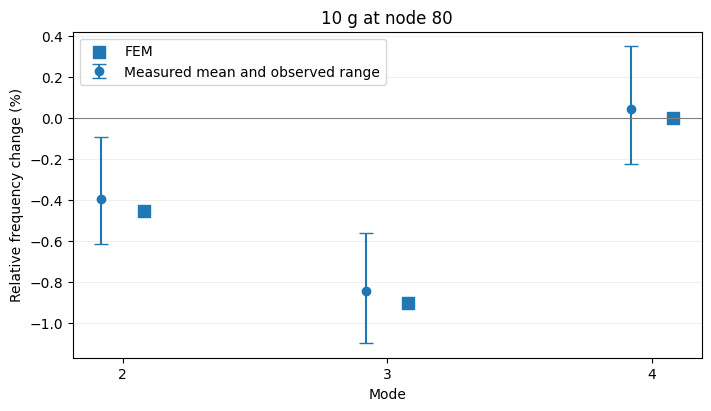

In [3]:
model = MassChanges.from_mat(BEAM)
f_ref = model.frequencies()
f_80_10 = model.frequencies(80, 0.010)
print('FEM reference [Hz]:', np.round(f_ref, 5))
print('FEM, node 80 and 10 g [Hz]:', np.round(f_80_10, 5))

modal = loadmat(MODAL)
cases_exp = modal['mfMassCase']
selected = np.all(cases_exp == [80, 10], axis=1)
assert selected.sum() == 45
shift_rows = 100 * (modal['mfFreqAna'][selected] / modal['mfFreqRef'][selected] - 1)
mean_shift = shift_rows.mean(axis=0)
fem_shift = 100 * (f_80_10[1:4] / f_ref[1:4] - 1)
print('Distinct measured configurations:', len(np.unique(cases_exp, axis=0)))
print('FEM shifts, modes 2–4 [%]:', np.round(fem_shift, 4))
print('Measured mean shifts, same modes [%]:', np.round(mean_shift, 4))

x = np.array([2, 3, 4])
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.errorbar(x-.08, mean_shift,
            yerr=[mean_shift-shift_rows.min(axis=0), shift_rows.max(axis=0)-mean_shift],
            fmt='o', capsize=5, label='Measured mean and observed range')
ax.scatter(x+.08, fem_shift, marker='s', s=65, label='FEM')
ax.axhline(0, color='0.5', lw=.8)
ax.set(xlabel='Mode', ylabel='Relative frequency change (%)', xticks=x,
       title='10 g at node 80')
ax.legend()
ax.grid(axis='y', alpha=.2)
plt.show()

## MATLAB–Python parity check

Six node–mass pairs are checked. On a Mac with MATLAB, the notebook calls the original class. In Docker, it checks against a compact reference generated by MATLAB R2025b and verifies the source file hashes first. Tolerances: matrices `rtol=atol=1e-12`; frequencies relative error `<1e-6`; objective absolute error `<1e-7`.

In [4]:
matlab_script = r"""
projectRoot = getenv('ML_STRUCTURAL_PROJECT');
outputFile = getenv('ML_STRUCTURAL_OUTPUT');
sourceRoot = fullfile(projectRoot,'data','extracted','Code_Veröffentlichung');
addpath(fullfile(sourceRoot,'Subclass'));
addpath(fullfile(sourceRoot,'Data','BeamData'));
beam = load(fullfile(sourceRoot,'Data','BeamData','LiveBeamData.mat'));
modal = load(fullfile(sourceRoot,'Data','ModalProperties','LiveBeamModalData.mat'));
row = find(modal.mfMassCase(:,1)==80 & modal.mfMassCase(:,2)==10,1,'first');
measuredReference = modal.mfFreqRef(row,:);
measuredModified = modal.mfFreqAna(row,:);
original = MassChanges(measuredReference,measuredModified,[2,3,4]);
rhoLs = beam.rhoLs;
width = rhoLs./(7850*0.003);
inertia = width*0.003^3/12;
EIs = 2.05e11.*inertia;
[Kassembled,Massembled] = original.AssembleMatrix(EIs,rhoLs);
fixedMasses = [73,.005;95,.005;117,.005;120,.005;22,.0206];
Mfixed = Massembled;
for j=1:size(fixedMasses,1)
    ix = (fixedMasses(j,1)-original.nFixture-1)*2+1;
    Mfixed(ix,ix) = Mfixed(ix,ix)+fixedMasses(j,2);
end
cases = [7,0;80,.010;40,.001;120,.050;22,.005;121,.100];
Mcases = zeros(size(Mfixed,1),size(Mfixed,2),size(cases,1));
frequenciesHz = zeros(size(cases,1),6);
frequenciesDenseHz = frequenciesHz;
for j=1:size(cases,1)
    M = Mfixed;
    ix = (round(cases(j,1))-original.nFixture-1)*2+1;
    M(ix,ix) = M(ix,ix)+cases(j,2);
    Mcases(:,:,j) = M;
    [~,D] = eigs(Kassembled,M,6,'smallestabs');
    frequenciesHz(j,:) = sort(sqrt(diag(D))/(2*pi)).';
    lambda = sort(real(eig(Kassembled,M)));
    frequenciesDenseHz(j,:) = (sqrt(lambda(1:6))/(2*pi)).';
end
objective80 = original.calculate([80,.010]);
matlabVersion = version;
save(outputFile,'cases','Kassembled','Massembled','Mfixed','Mcases', ...
    'frequenciesHz','frequenciesDenseHz','objective80', ...
    'measuredReference','measuredModified','matlabVersion','-v7');
"""

if MATLAB.is_file() and os.environ.get('ML_STRUCTURAL_FORCE_REFERENCE') != '1':
    with TemporaryDirectory(prefix='hannover-parity-') as folder:
        script = Path(folder) / 'run_parity.m'
        output = Path(folder) / 'matlab_results.mat'
        script.write_text(matlab_script)
        env = os.environ.copy()
        env['ML_STRUCTURAL_PROJECT'] = str(PROJECT)
        env['ML_STRUCTURAL_OUTPUT'] = str(output)
        subprocess.run([str(MATLAB), '-batch', f"run('{script.as_posix()}')"],
                       cwd=PROJECT, env=env, capture_output=True, text=True,
                       timeout=600, check=True)
        matlab = loadmat(output)
    parity_source = 'live MATLAB'
else:
    with np.load(PARITY_REFERENCE) as saved:
        matlab = {key: saved[key] for key in saved.files}
    expected = {'sha_beam': BEAM, 'sha_original': ORIGINAL, 'sha_python': PYTHON}
    for key, path in expected.items():
        assert str(matlab[key].item()) == digest(path), f'Reference does not match {path.name}'
    parity_source = 'saved MATLAB R2025b reference (MATLAB not executed)'
print('Parity source:', parity_source)
print('MATLAB version:', str(matlab['matlabVersion'].item()))
print('Cases:', [(int(node), float(kg)) for node, kg in matlab['cases']])


Parity source: live MATLAB
MATLAB version: 25.2.0.3360999 (R2025b) Update 7
Cases: [(7, 0.0), (80, 0.01), (40, 0.001), (120, 0.05), (22, 0.005), (121, 0.1)]


In [5]:
k, m = model.assemble_matrices()
m_fixed = m.copy()
for node, kg in model.FIXED_MASSES:
    model._add_point_mass(m_fixed, node, kg)
matrix_pairs = [(k, matlab['Kassembled']), (m, matlab['Massembled']),
                (m_fixed, matlab['Mfixed'])]
python_frequencies = []
for i, (node, kg) in enumerate(matlab['cases']):
    node, kg = int(node), float(kg)
    m_case = m_fixed.copy()
    model._add_point_mass(m_case, node, kg)
    matrix_pairs.append((m_case, matlab['Mcases'][:, :, i]))
    python_frequencies.append(model.frequencies(node, kg))
python_frequencies = np.asarray(python_frequencies)
matlab_frequencies = matlab['frequenciesHz']
frequency_abs = np.abs(python_frequencies-matlab_frequencies)
frequency_rel = frequency_abs/matlab_frequencies
k_rel = np.linalg.norm(k-matlab['Kassembled'])/np.linalg.norm(matlab['Kassembled'])
mass_max = max(np.max(np.abs(a-b)) for a,b in matrix_pairs[1:])
objective_error = abs(model.objective(80,.010,matlab['measuredReference'],
                    matlab['measuredModified'],(2,3,4))-float(matlab['objective80'].item()))

assert all(np.allclose(a,b,rtol=1e-12,atol=1e-12) for a,b in matrix_pairs)
assert frequency_rel.max() < 1e-6
assert objective_error < 1e-7
assert all(digest(p)==h for p,h in input_hashes.items())

rows = ['| Node | Added mass (g) | Largest frequency error (Hz) |',
        '|---:|---:|---:|']
for i,(node,kg) in enumerate(matlab['cases']):
    rows.append(f'| {int(node)} | {kg*1000:g} | {frequency_abs[i].max():.3g} |')
display(Markdown('\n'.join(rows)))
print(f'PASS: K relative difference {k_rel:.3g}; mass matrix maximum difference {mass_max:.3g}')
print(f'Maximum frequency difference {frequency_abs.max():.3g} Hz '
      f'(relative {frequency_rel.max():.3g}); objective difference {objective_error:.3g}')
print('MATLAB eigs versus MATLAB dense eig, maximum difference:',
      f"{np.max(np.abs(matlab['frequenciesHz']-matlab['frequenciesDenseHz'])):.3g} Hz")

| Node | Added mass (g) | Largest frequency error (Hz) |
|---:|---:|---:|
| 7 | 0 | 7.02e-07 |
| 80 | 10 | 6.27e-07 |
| 40 | 1 | 1.65e-06 |
| 120 | 50 | 1.64e-06 |
| 22 | 5 | 7.15e-07 |
| 121 | 100 | 2.82e-07 |

PASS: K relative difference 1.5e-16; mass matrix maximum difference 0
Maximum frequency difference 1.65e-06 Hz (relative 5.26e-07); objective difference 1.13e-08
MATLAB eigs versus MATLAB dense eig, maximum difference: 1.88e-06 Hz


## FEM versus all measured configurations

The experimental file has 34 configurations with added mass. Its three frequency columns are compared with FEM modes 2–4, as in the original MATLAB study. Each configuration receives **one vote** in the summary, even though it has 40 or 45 repeated frequency estimates.

For one configuration and one mode:

- **Modified frequency error (Hz):** FEM frequency with the mass minus the mean measured frequency with that mass. The **modified MAE** is the mean of its absolute value over the 34 configurations. It answers: *How close is the final frequency?*
- **Relative shift (%):** $100(f_{\mathrm{with\ mass}}/f_{\mathrm{reference}}-1)$. For the experiment, calculate this shift for each paired estimate, then average within its configuration. The **shift MAE** is the mean absolute difference between the FEM and measured shifts over the 34 configurations. It answers: *How well does the FEM predict the effect of adding mass?* The difference between two percentages is in **percentage points (pp)**.
- **Bias:** the mean **signed** FEM-minus-measurement difference. A positive bias means the FEM tends to predict a higher frequency or a less negative shift; positive and negative errors can cancel. The reference bias uses the FEM reference minus the mean of the 34 configuration-specific measured references.

**Example — mode 2, 80 cm and 10 g:** FEM changes from 13.8379 to 13.7753 Hz; the measured means are about 13.8892 and 13.8345 Hz. The modified frequency error is about **−0.059 Hz**. The FEM shift is **−0.452%**, while the mean measured shift is **−0.394%**: an error of about **−0.058 pp**. The MAEs below average the error magnitudes over all configurations, so they differ from this single example.

The ranges in plots show observed repeated estimates, not independent experiments or confidence intervals.

In [6]:
unique_cases, case_counts = np.unique(cases_exp, axis=0, return_counts=True)
added_cases = unique_cases[unique_cases[:, 1] > 0]
assert len(added_cases) == 34
fem_reference = f_ref[1:4]
fem_modified, measured_reference, measured_modified, measured_shifts = [], [], [], []
for node, grams in added_cases:
    rows = np.all(cases_exp == [node, grams], axis=1)
    fem_modified.append(model.frequencies(int(node), grams/1000)[1:4])
    measured_reference.append(modal['mfFreqRef'][rows].mean(axis=0))
    measured_modified.append(modal['mfFreqAna'][rows].mean(axis=0))
    measured_shifts.append((100*(modal['mfFreqAna'][rows]/modal['mfFreqRef'][rows]-1)).mean(axis=0))
fem_modified = np.asarray(fem_modified)
measured_reference = np.asarray(measured_reference)
measured_modified = np.asarray(measured_modified)
measured_shifts = np.asarray(measured_shifts)
fem_shifts = 100*(fem_modified/fem_reference-1)
shift_error = fem_shifts-measured_shifts
absolute_error = fem_modified-measured_modified

assert sum(case_counts[unique_cases[:, 1] > 0]) == 1520
summary = ['| FEM mode | Reference bias (Hz) | Modified MAE (Hz) | Shift MAE (pp) | Shift bias (pp) |',
           '|---:|---:|---:|---:|---:|']
for j, mode in enumerate([2, 3, 4]):
    summary.append(f'| {mode} | {fem_reference[j]-measured_reference[:,j].mean():+.3f} '
                   f'| {np.abs(absolute_error[:,j]).mean():.3f} '
                   f'| {np.abs(shift_error[:,j]).mean():.3f} '
                   f'| {shift_error[:,j].mean():+.3f} |')
display(Markdown('\n'.join(summary)))
print('Added-mass configurations:', len(added_cases), '| repeated estimates:',
      sum(case_counts[unique_cases[:, 1] > 0]))
for j, mode in enumerate([2, 3, 4]):
    worst = np.argmax(np.abs(shift_error[:,j]))
    print(f'Mode {mode}: largest shift error {shift_error[worst,j]:+.3f} pp '
          f'at {added_cases[worst,0]:g} cm and {added_cases[worst,1]:g} g')

| FEM mode | Reference bias (Hz) | Modified MAE (Hz) | Shift MAE (pp) | Shift bias (pp) |
|---:|---:|---:|---:|---:|
| 2 | -0.055 | 0.047 | 0.093 | +0.050 |
| 3 | -0.211 | 0.269 | 0.217 | -0.178 |
| 4 | +0.719 | 0.611 | 0.256 | -0.167 |

Added-mass configurations: 34 | repeated estimates: 1520
Mode 2: largest shift error +0.419 pp at 100 cm and 50 g
Mode 3: largest shift error -0.825 pp at 100 cm and 50 g
Mode 4: largest shift error -1.317 pp at 100 cm and 50 g


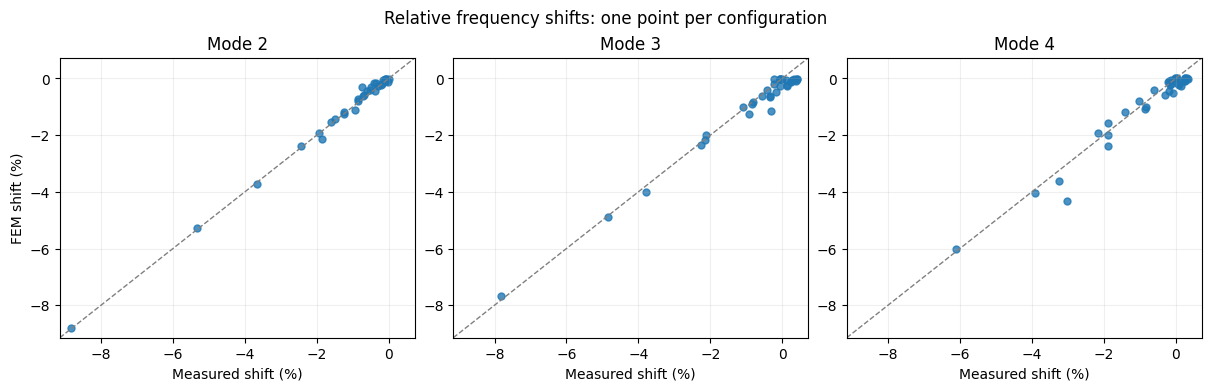

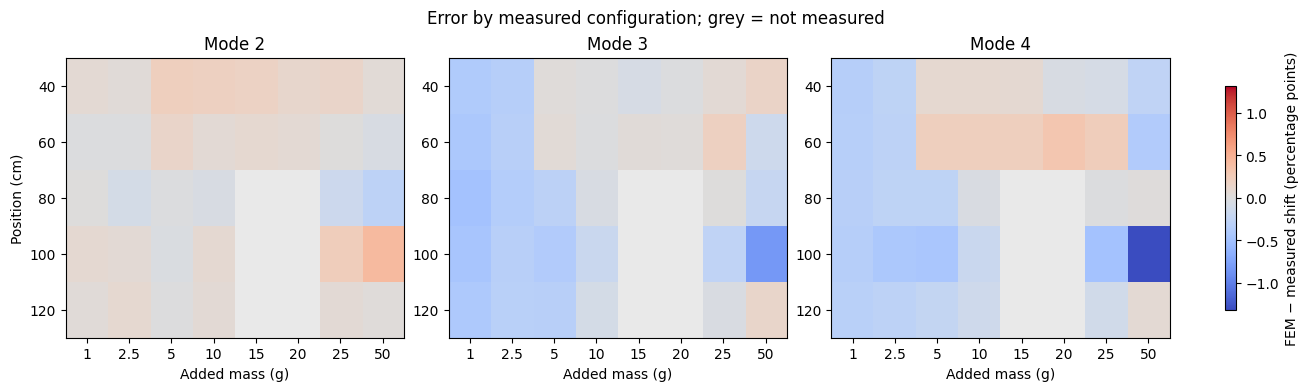

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
limits = [min(measured_shifts.min(), fem_shifts.min())-.3,
          max(measured_shifts.max(), fem_shifts.max())+.3]
for j, (ax, mode) in enumerate(zip(axes, [2, 3, 4])):
    ax.scatter(measured_shifts[:,j], fem_shifts[:,j], s=25, alpha=.8)
    ax.plot(limits, limits, '--', color='0.5', lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel='Measured shift (%)',
           ylabel='FEM shift (%)' if j==0 else '', title=f'Mode {mode}')
    ax.grid(alpha=.2)
fig.suptitle('Relative frequency shifts: one point per configuration')
plt.show()

positions = np.unique(added_cases[:,0]); masses = np.unique(added_cases[:,1])
error_grid = np.full((3, len(positions), len(masses)), np.nan)
for i, (position, mass) in enumerate(added_cases):
    pi = np.flatnonzero(positions==position)[0]
    mi = np.flatnonzero(masses==mass)[0]
    error_grid[:,pi,mi] = shift_error[i]
limit = max(.1, np.nanmax(np.abs(error_grid)))
cmap = plt.colormaps['coolwarm'].copy(); cmap.set_bad('#e9e9e9')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for j, (ax, mode) in enumerate(zip(axes, [2, 3, 4])):
    image = ax.imshow(np.ma.masked_invalid(error_grid[j]), cmap=cmap,
                      vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=np.arange(len(masses)), xticklabels=[f'{g:g}' for g in masses],
           yticks=np.arange(len(positions)), yticklabels=[f'{cm:g}' for cm in positions],
           xlabel='Added mass (g)', ylabel='Position (cm)' if j==0 else '',
           title=f'Mode {mode}')
fig.colorbar(image, ax=axes, shrink=.8, label='FEM − measured shift (percentage points)')
fig.suptitle('Error by measured configuration; grey = not measured')
plt.show()

### How each mode changes as mass increases

Each panel is one mode. The horizontal axis is added mass; line color identifies its position. **Solid** lines are FEM predictions and **dashed** lines are measured mean shifts. A missing point means that combination was not measured.

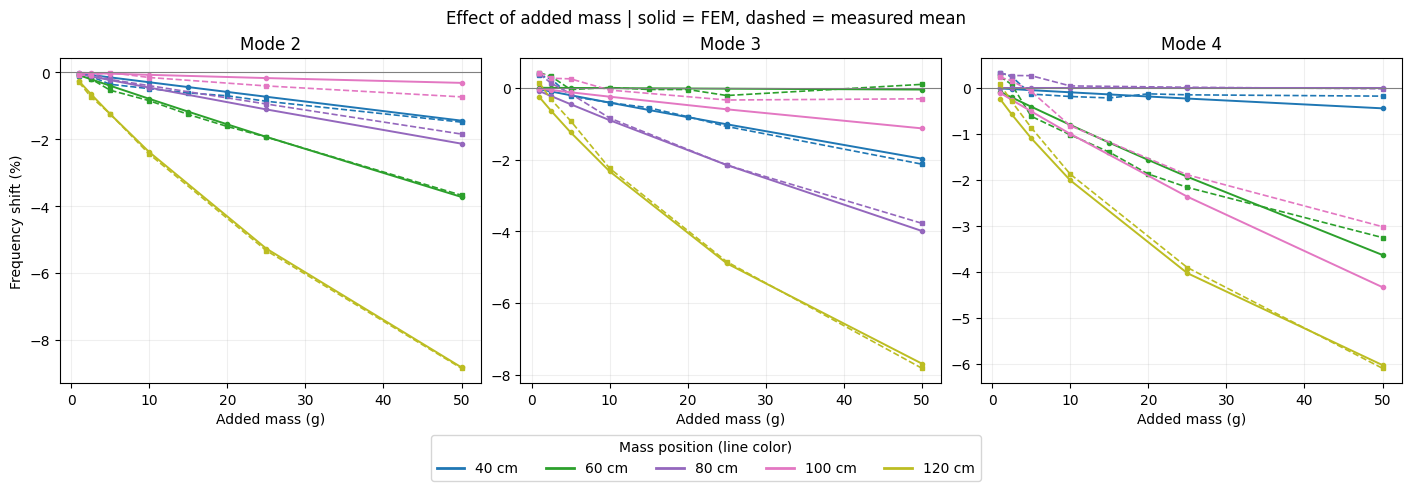

In [8]:
from matplotlib.lines import Line2D

colors = dict(zip(positions, plt.colormaps['tab10'](np.linspace(0, .8, len(positions)))))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), layout='constrained', sharex=True)
for j, (ax, mode) in enumerate(zip(axes, [2, 3, 4])):
    for position in positions:
        mask = added_cases[:, 0] == position
        mass_values = added_cases[mask, 1]
        ax.plot(mass_values, fem_shifts[mask, j], '-o', color=colors[position],
                markersize=3, linewidth=1.4)
        ax.plot(mass_values, measured_shifts[mask, j], '--s', color=colors[position],
                markersize=3, linewidth=1.2)
    ax.axhline(0, color='0.5', linewidth=.8)
    ax.set(xlabel='Added mass (g)', ylabel='Frequency shift (%)' if j == 0 else '',
           title=f'Mode {mode}')
    ax.grid(alpha=.2)
position_handles = [Line2D([0], [0], color=colors[p], lw=2, label=f'{p:g} cm')
                    for p in positions]
fig.legend(handles=position_handles, loc='outside lower center', ncol=len(positions),
           title='Mass position (line color)')
fig.suptitle('Effect of added mass | solid = FEM, dashed = measured mean')
plt.show()

**Conclusion.** Python agrees with the MATLAB results within the stated numerical tolerances (live MATLAB when available, otherwise the checked R2025b reference). Against experiments, the FEM has nonzero bias in absolute frequencies and relative shifts; the table and plots quantify both across all 34 added-mass configurations. The largest shift errors occur at 100 cm / 50 g. These differences are FEM-versus-measurement errors, not Python-versus-MATLAB errors. Small positive measured shifts in some modes can reflect measurement variability or unmodelled effects; the FEM with added positive mass predicts no positive shifts here. The 1,520 repeated estimates do not represent 1,520 independent structures.